In [9]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("crisparada/brazilian-cities")

print("Path to dataset files:", path)

Path to dataset files: /home/evssz/.cache/kagglehub/datasets/crisparada/brazilian-cities/versions/5


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Random Forest: predicción de IDHM en ciudades brasileñas

### 1. Lectura de datos

In [11]:
df = pd.read_csv(f"{path}/BRAZIL_CITIES.csv", sep=";", decimal=",")
df.columns = df.columns.str.strip()   # ' GVA_TOTAL' trae un espacio al inicio
print(df.shape)
df.head()

(5573, 81)


,CITY,STATE,CAPITAL,IBGE_RES_POP,IBGE_RES_POP_BRAS,IBGE_RES_POP_ESTR,IBGE_DU,IBGE_DU_URBAN,IBGE_DU_RURAL,IBGE_POP,...,Pu_Bank,Pr_Assets,Pu_Assets,Cars,Motorcycles,Wheeled_tractor,UBER,MAC,WAL-MART,POST_OFFICES
0,Abadia De Goiás,GO,0,6876.0,6876.0,0.0,2137.0,1546.0,591.0,5300.0,...,NaN,NaN,NaN,2158.0,1246.0,0.0,NaN,NaN,NaN,1.0
1,Abadia Dos Dourados,MG,0,6704.0,6704.0,0.0,2328.0,1481.0,847.0,4154.0,...,NaN,NaN,NaN,2227.0,1142.0,0.0,NaN,NaN,NaN,1.0
2,Abadiânia,GO,0,15757.0,15609.0,148.0,4655.0,3233.0,1422.0,10656.0,...,1.0,33724584.0,67091904.0,2838.0,1426.0,0.0,NaN,NaN,NaN,3.0
3,Abaeté,MG,0,22690.0,22690.0,0.0,7694.0,6667.0,1027.0,18464.0,...,2.0,44974716.0,371922572.0,6928.0,2953.0,0.0,NaN,NaN,NaN,4.0
4,Abaetetuba,PA,0,141100.0,141040.0,60.0,31061.0,19057.0,12004.0,82956.0,...,4.0,76181384.0,800078483.0,5277.0,25661.0,0.0,NaN,NaN,NaN,2.0


### 2. Eliminación de columnas indicadas

In [12]:
cols_drop = ["CITY", "IDHM Ranking 2010", "IDHM_Renda", "IDHM_Longevidade", "IDHM_Educacao",
             "LONG", "LAT", "GVA_MAIN", "REGIAO_TUR", "MUN_EXPENDIT", "HOTELS", "BEDS",
             "Pr_Agencies", "Pu_Agencies", "Pr_Bank", "Pu_Bank", "Pr_Assets", "Pu_Assets",
             "UBER", "MAC", "WAL-MART"]
df = df.drop(columns=cols_drop)
print(df.shape)

(5573, 60)


### 3. Limpieza y transformación
- Varias columnas numéricas (`IDHM`, `AREA`, `GDP`, `GVA_*`, ...) se leen como texto: usan `.` decimal y/o `,` como separador de miles. Se quita la coma y se convierte con `to_numeric`.
- `IDHM` es el objetivo: se eliminan las 8 filas sin valor.
- Categóricas (`STATE`, `RURAL_URBAN`, `CATEGORIA_TUR`): *one-hot encoding*. Son nominales sin orden, así que un código entero (label encoding) inventaría un orden falso. `CATEGORIA_TUR` nulo significa que el municipio no está en el mapa turístico: se rellena con `Sin_turismo`.
- Numéricas con nulos: imputación con la mediana (robusta a la fuerte asimetría de poblaciones y PIB).

In [13]:
cat_cols = ["STATE", "RURAL_URBAN", "CATEGORIA_TUR"]
for c in df.columns.difference(cat_cols):
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = pd.to_numeric(df[c].str.replace(",", "", regex=False), errors="coerce")

df = df.dropna(subset=["IDHM"])
df["CATEGORIA_TUR"] = df["CATEGORIA_TUR"].fillna("Sin_turismo")
df["RURAL_URBAN"] = df["RURAL_URBAN"].fillna("Sem classificação")

X = pd.get_dummies(df.drop(columns="IDHM"), columns=cat_cols, drop_first=True)
X = X.fillna(X.median())
y = df["IDHM"]
print(X.shape, "nulos:", X.isna().sum().sum())

(5565, 92) nulos: 0


### 4. Separación 70/30 y entrenamiento

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10)

rf = RandomForestRegressor(n_estimators=300, random_state=10, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

### 5. Métricas en prueba

In [15]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"R²   : {r2:.4f}")
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")

R²   : 0.8708
MAE  : 0.0200
RMSE : 0.0261


### 6. Gráficos: real vs. predicho e importancia de variables

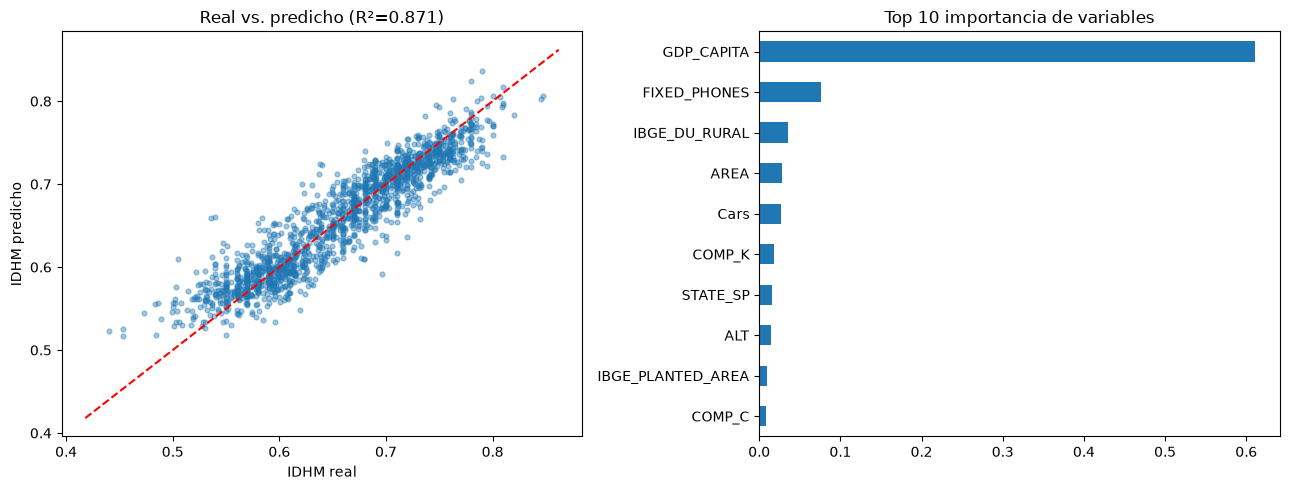

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, y_pred, alpha=0.4, s=12)
lim = [y.min(), y.max()]
ax[0].plot(lim, lim, "r--")
ax[0].set(xlabel="IDHM real", ylabel="IDHM predicho", title=f"Real vs. predicho (R²={r2:.3f})")

imp = pd.Series(rf.feature_importances_, index=X.columns).nlargest(10).sort_values()
imp.plot.barh(ax=ax[1], title="Top 10 importancia de variables")
plt.tight_layout()
plt.show()

### 7. Experimento opcional: PCA a 15 dimensiones
Se escala (PCA es sensible a la escala) y se ajusta **solo con el train** para evitar fuga de información; luego se entrena el mismo Random Forest sobre los 15 componentes y se compara.

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler().fit(X_train)
pca = PCA(n_components=15, random_state=10).fit(scaler.transform(X_train))
Z_train = pca.transform(scaler.transform(X_train))
Z_test = pca.transform(scaler.transform(X_test))
print(f"Varianza explicada por 15 componentes: {pca.explained_variance_ratio_.sum():.2%}")

rf_pca = RandomForestRegressor(n_estimators=300, random_state=10, n_jobs=-1)
rf_pca.fit(Z_train, y_train)
y_pred_pca = rf_pca.predict(Z_test)

resultados = pd.DataFrame({
    "R²": [r2, r2_score(y_test, y_pred_pca)],
    "MAE": [mae, mean_absolute_error(y_test, y_pred_pca)],
    "RMSE": [rmse, np.sqrt(mean_squared_error(y_test, y_pred_pca))],
}, index=[f"Sin PCA ({X.shape[1]} variables)", "Con PCA (15 componentes)"])
resultados.round(4)

Varianza explicada por 15 componentes: 72.45%


,R²,MAE,RMSE
Sin PCA (92 variables),0.8708,0.0200,0.0261
Con PCA (15 componentes),0.8234,0.0234,0.0306


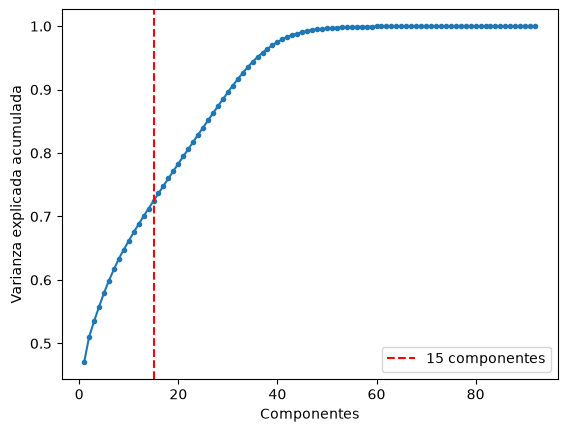

In [18]:
cum = np.cumsum(PCA().fit(scaler.transform(X_train)).explained_variance_ratio_)
plt.plot(range(1, len(cum) + 1), cum, marker=".")
plt.axvline(15, color="r", ls="--", label="15 componentes")
plt.xlabel("Componentes"); plt.ylabel("Varianza explicada acumulada"); plt.legend()
plt.show()

### 8. Interpretación
- **R² ≈ 0,87**: el modelo explica cerca del 87 % de la varianza del IDHM en municipios no vistos.
- **MAE ≈ 0,020 y RMSE ≈ 0,026**: el error típico es de ~0,02 puntos sobre un IDHM que va de 0,42 a 0,86 (desv. estándar 0,072), es decir, un error de ~3 %. El RMSE algo mayor que el MAE indica algunos errores grandes puntuales.
- **Variable dominante**: `GDP_CAPITA` (~61 % de la importancia), seguida de teléfonos fijos, población rural en viviendas, área y autos: desarrollo humano ligado a riqueza y a infraestructura.
- **PCA (15 componentes)**: retiene solo ~72 % de la varianza y empeora el modelo (R² 0,871 → 0,823; MAE 0,020 → 0,023; RMSE 0,026 → 0,031). Las variables originales ya eran informativas por sí solas y el bosque tolera la multicolinealidad; comprimir descarta señal (p. ej. `GDP_CAPITA`, la variable clave, queda diluida en componentes) y además pierde interpretabilidad. Por eso el modelo final es el **sin PCA**.